In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/playground-series-s5e1/sample_submission.csv
/kaggle/input/competitions/playground-series-s5e1/train.csv
/kaggle/input/competitions/playground-series-s5e1/test.csv
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/model_xgb_target.pkl
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/model_xgb_onehot_tr.pkl
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/permutation_result_xgb_onehot.pkl
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/permutation_result.pkl
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/model_xgb.pkl
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/X_test.parquet
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/model_xgb_onehot.pkl
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/study_xgb.pkl
/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/permutation_result_xgb_onehot_tr.pkl
/kaggle/input/notebooks/davibaca/forecasting-sti

In [2]:
!pip install -U scikit-learn
import sklearn
print(sklearn.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 67.4 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
1.9.1


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
color_pal = sns.color_palette()
import joblib
import json
import optuna
import optuna.visualization as vis
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    mean_absolute_percentage_error, root_mean_squared_error,
    root_mean_squared_log_error
)
from sklearn.model_selection import cross_val_score, learning_curve, TimeSeriesSplit
from optuna.pruners import MedianPruner
from functools import partial
import tensorflow as tf

In [4]:
def sine_cosine_encoding(df):
    df = df.copy()

    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
    df['dayofweek_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
    df['dayofweek_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)
    df['dayofyear_sin'] = np.sin(2 * np.pi * df['dayofyear'] / 365)
    df['dayofyear_cos'] = np.cos(2 * np.pi * df['dayofyear'] / 365)
    df['weekofyear_sin'] = np.sin(2 * np.pi * df['weekofyear'] / 52)
    df['weekofyear_cos'] = np.cos(2 * np.pi * df['weekofyear'] / 52)

    df = df.drop(columns=['month', 'dayofweek', 'dayofyear', 'weekofyear'])

    return df

#####################################################################
# METRICS
#####################################################################
tscv = TimeSeriesSplit(n_splits=5)

def cross_val(model, X_train, y_train, name=""):
    scores = -cross_val_score(model, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
    print(f"--- {name}: Cross-validation (5 folds) ---")
    print(f"RMSE por fold: {np.round(scores, 4)}")
    print(f"Media: {scores.mean():.4f} | Std: {scores.std():.4f} | CV%: {scores.std()/scores.mean()*100:.2f}%")
    return {'cv_mean': scores.mean(), 'cv_std': scores.std()}
    
def cross_val_mlp(params, X, y, tscv):
    scores = []

    for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):

        X_tr = X.iloc[train_idx] if hasattr(X, "iloc") else X[train_idx]
        X_va = X.iloc[val_idx] if hasattr(X, "iloc") else X[val_idx]

        y_tr = y.iloc[train_idx] if hasattr(y, "iloc") else y[train_idx]
        y_va = y.iloc[val_idx] if hasattr(y, "iloc") else y[val_idx]

        model = Sequential([
            Dense(256, activation="relu",
                  input_shape=(X_tr.shape[1],)),
            BatchNormalization(),
            Dropout(0.4),

            Dense(128, activation="relu"),
            BatchNormalization(),
            Dropout(0.4),

            Dense(64, activation="relu"),
            Dropout(0.3),

            Dense(1)
        ])

        model.compile(
            optimizer=Adam(
                learning_rate=params.get("learning_rate", 0.0005)
            ),
            loss="mse",
            metrics=["mae"]
        )

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=20,
            restore_best_weights=True
        )

        model.fit(
            X_tr, np.asarray(y_tr).reshape(-1),
            validation_data=(
                X_va, np.asarray(y_va).reshape(-1)
            ),
            epochs=params.get("epochs", 100),
            batch_size=params.get("batch_size", 256),
            callbacks=[early_stop],
            verbose=0
        )

        pred = model.predict(X_va, verbose=0).flatten()

        rmse = root_mean_squared_error(
            np.asarray(y_va).reshape(-1), pred
        )

        scores.append(rmse)
        print(f"Fold {fold + 1}: {rmse:.4f}")

    print(f"CV mean: {np.mean(scores):.4f}")
    print(f"CV std: {np.std(scores):.4f}")

    return np.array(scores)
    

def plot_learning_curve(model, X_train, y_train, name=""):
    X = np.asarray(X_train, dtype=np.float32)
    y = np.asarray(y_train).reshape(-1)

    train_sizes = np.linspace(0.1, 1.0, 5)
    train_rmse, val_rmse = [], []

    splits = list(tscv.split(X))
    train_idx, val_idx = splits[-1]

    X_tr, y_tr = X[train_idx], y[train_idx]
    X_val, y_val = X[val_idx], y[val_idx]

    for size in train_sizes:
        n = max(1, int(len(X_tr) * size))

        model_lc = tf.keras.models.clone_model(model)
        model_lc.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
            loss="mse",
            metrics=["mae"]
        )

        model_lc.fit(
            X_tr[:n], y_tr[:n],
            validation_data=(X_val, y_val),
            epochs=100,
            batch_size=256,
            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=10,
                    restore_best_weights=True
                )
            ],
            verbose=0
        )

        pred_train = model_lc.predict(X_tr[:n], verbose=0).flatten()
        pred_val = model_lc.predict(X_val, verbose=0).flatten()

        train_rmse.append(root_mean_squared_error(y_tr[:n], pred_train))
        val_rmse.append(root_mean_squared_error(y_val, pred_val))

    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes * len(X_tr), train_rmse, marker="o", label="Train RMSE")
    plt.plot(train_sizes * len(X_tr), val_rmse, marker="o", label="Validation RMSE")
    plt.xlabel("Training samples")
    plt.ylabel("RMSE")
    plt.title(f"Learning Curve - {name}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    
def evaluate_additional_metrics(y_true, y_pred, name=""):
    errors = y_true - y_pred
    error_pct = np.abs(errors / y_true) * 100

    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape_val = mean_absolute_percentage_error(y_true, y_pred) * 100
    try:
        rmsle = root_mean_squared_log_error(y_true, y_pred)
    except ValueError:
        rmsle = None  # fails if there are negative predictions

    print(f"--- {name}: Additional metrics ---")
    print(f"MAE: {mae:.4f} | MAPE: {mape_val:.2f}% | R²: {r2:.4f}", end="")
    print(f" | RMSLE: {rmsle:.4f}" if rmsle is not None else " | RMSLE: N/A (negative predictions)")
    print(f"Bias (mean error): {errors.mean():.4f}")
    print(f"Prediction std: {y_pred.std():.4f} | Real std: {y_true.std():.4f}")
    for tol in [10, 15, 20]:
        successes = (error_pct <= tol).mean() * 100
        print(f"Within ±{tol}%: {successes:.2f}%")
        
def evaluate_gap(y_train, pred_train, y_val, pred_val, name=""):
    rmse_train = root_mean_squared_error(y_train, pred_train)
    rmse_val = root_mean_squared_error(y_val, pred_val)
    gap = rmse_val - rmse_train
    gap_pct = gap / rmse_train * 100

    print(f"--- {name}: Train vs Val ---")
    print(f"RMSE train: {rmse_train:.4f} | RMSE val: {rmse_val:.4f}")
    print(f"Gap: {gap:.4f} ({gap_pct:.2f}%)")

    return {'rmse_train': rmse_train, 'rmse_val': rmse_val, 'gap_pct': gap_pct}

In [5]:
# DataFrame with testing data
test_df = pd.read_csv('/kaggle/input/competitions/playground-series-s5e1/test.csv',parse_dates=["date"])

In [6]:
X_test = pd.read_parquet("/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/X_test.parquet")
X_train = pd.read_parquet("/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/X_train.parquet")
X_val = pd.read_parquet("/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/X_val.parquet")
y_train = pd.read_parquet("/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/y_train.parquet")
y_val = pd.read_parquet("/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/y_val.parquet")
y_train = np.asarray(y_train).reshape(-1)
y_val = np.asarray(y_val).reshape(-1)

In [7]:
X_train.head()

,country_store_encoded,store_product_encoded,country_product_encoded,country_store_product_encoded,target_enc__country,target_enc__store,target_enc__product,Time,dayofweek,quarter,...,country_Norway,country_Singapore,store_Discount Stickers,store_Premium Sticker Mart,store_Stickers for Less,product_Holographic Goose,product_Kaggle,product_Kaggle Tiers,product_Kerneler,product_Kerneler Dark Mode
0,751.384151,751.384151,751.384151,751.384151,792.994631,416.722492,179.247020,0,4,1,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,751.384151,751.384151,751.384151,751.384151,793.095483,416.657389,1277.134330,0,4,1,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,751.384151,751.384151,751.384151,751.384151,790.406373,416.361791,1055.529429,0,4,1,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,751.384151,751.384151,751.384151,751.384151,792.994631,416.722492,575.661814,0,4,1,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,751.384151,751.384151,751.384151,751.384151,793.095483,416.657389,674.478029,0,4,1,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [8]:
X_train_xgb = X_train.drop(['Time','year', 'product_Kerneler Dark Mode','dayofmonth', 'country_Finland', 'product_Kerneler', 'store_Premium Sticker Mart', 'store_Stickers for Less', 'country_Italy', 'country_product_encoded',  'country_Norway', 'yearlag2',  'store_product_encoded', 'country_store_encoded'], axis=1).copy()

In [9]:
# Interaction values (more expensive than regular SHAP — use a smaller sample)

model_xgb = joblib.load('/kaggle/input/notebooks/davibaca/forecasting-sticker-sales-ml/model_xgb.pkl')

import shap

SAMPLE_SIZE_INTERACTION = 10000
X_interaction_sample = X_train_xgb.sample(n=SAMPLE_SIZE_INTERACTION, random_state=42)
explainer_xgb = shap.TreeExplainer(model_xgb)
shap_interaction_values = explainer_xgb.shap_interaction_values(X_interaction_sample)

# Average absolute interaction strength between every pair of features
interaction_matrix = np.abs(shap_interaction_values).mean(axis=0)

interaction_df = pd.DataFrame(
    interaction_matrix, 
    index=X_interaction_sample.columns, 
    columns=X_interaction_sample.columns
)

# Extract the top interacting pairs (excluding the diagonal, which is each feature's own effect)
np.fill_diagonal(interaction_df.values, 0)

top_interactions = (
    interaction_df.where(np.triu(np.ones(interaction_df.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
    .head(20)
)

print("Top 20 feature interactions:")
print(top_interactions)

/usr/lib/python3.13/pickle.py:1754: UserWarning: [22:30:43] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


Top 20 feature interactions:
target_enc__country            yearlag1                     0.022874
country_store_product_encoded  target_enc__product          0.019394
target_enc__product            yearlag1                     0.019086
country_store_product_encoded  target_enc__country          0.018705
yearlag1                       gdp_factor                   0.012585
country_store_product_encoded  yearlag1                     0.012566
                               country_Kenya                0.012147
yearlag1                       country_Kenya                0.010878
                               store_Discount Stickers      0.008861
country_store_product_encoded  product_Holographic Goose    0.008472
                               gdp_factor                   0.006759
target_enc__product            gdp_factor                   0.006246
yearlag1                       product_Holographic Goose    0.005461
country_store_product_encoded  target_enc__store            0.005155
targe

In [10]:
X_test = sine_cosine_encoding(X_test)
X_train = sine_cosine_encoding(X_train)
X_val = sine_cosine_encoding(X_val)

X_test = X_test.drop(['yearlag1', 'yearlag2'], axis=1)
X_train = X_train.drop(['yearlag1', 'yearlag2'], axis=1)
X_val = X_val.drop(['yearlag1', 'yearlag2'], axis=1)

In [11]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping 
from tensorflow.keras.optimizers import Adam
import pickle

scaler_mlp = StandardScaler()
X_train_scaled = scaler_mlp.fit_transform(X_train)
X_val_scaled = scaler_mlp.transform(X_val)
X_test_scaled = scaler_mlp.transform(X_test)

In [12]:
X_train_scaled.shape

(164430, 34)

In [13]:
model_mlp = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1)
])

model_mlp.compile(optimizer=Adam(learning_rate=0.0005), loss='mse', metrics=['mae'])

checkpoint_mlp = ModelCheckpoint("/kaggle/working/best_mlp.keras",
                                 monitor='val_loss',
                                 save_best_only=True)

early_stop_mlp = EarlyStopping(monitor='val_loss',
                               patience=20,
                               restore_best_weights=True)

history_mlp = model_mlp.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[checkpoint_mlp, early_stop_mlp],
    verbose=1
)

#Save history
with open('history_mlp.pkl', 'wb') as f:
    pickle.dump(history_mlp, f)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-13 22:30:52.313686: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 502148.2812 - mae: 488.1227 - val_loss: 52014.7500 - val_mae: 168.4752
Epoch 2/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 52620.6211 - mae: 160.2113 - val_loss: 14963.7822 - val_mae: 76.5945
Epoch 3/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 43162.6406 - mae: 139.2971 - val_loss: 14306.9277 - val_mae: 75.6134
Epoch 4/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 40684.0352 - mae: 133.7851 - val_loss: 12085.6270 - val_mae: 70.8993
Epoch 5/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 40020.4766 - mae: 131.2722 - val_loss: 10706.1016 - val_mae: 62.9158
Epoch 6/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 38764.1289 - mae: 128.0658 - val_loss: 10595.2549 - val_mae: 64.1936
Epoch 7/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 37923.3906 - mae: 125.1236 - val_loss: 9760.3271 - val_mae: 63.7009
Epoch 8/100
643/643 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 36980.3203 - mae: 122.7331

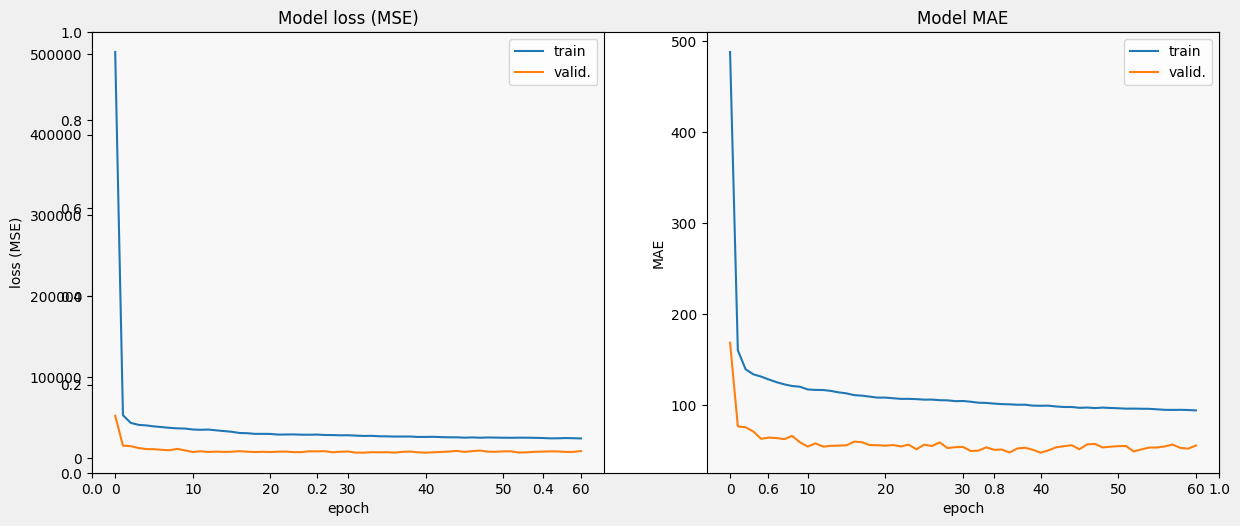

In [14]:
def display_training_curves(training, validation, title, subplot):
    if subplot % 10 == 1:
        plt.subplots(figsize=(12, 5), facecolor='#F0F0F0')
        plt.tight_layout()
    ax = plt.subplot(subplot)
    ax.set_facecolor('#F8F8F8')
    ax.plot(training)
    ax.plot(validation)
    ax.set_title('Model ' + title)
    ax.set_ylabel(title)
    ax.set_xlabel('epoch')
    ax.legend(['train', 'valid.'])

display_training_curves(
    history_mlp.history['loss'],
    history_mlp.history['val_loss'],
    'loss (MSE)',
    121,
)
display_training_curves(
    history_mlp.history['mae'],
    history_mlp.history['val_mae'],
    'MAE',
    122,
)
plt.show()

5139/5139 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
2054/2054 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
--- MLP: Train vs Val ---
RMSE train: 75.8148 | RMSE val: 79.0758
Gap: 3.2610 (4.30%)
--- MLP: Additional metrics ---
MAE: 47.6348 | MAPE: 14.02% | R²: 0.9827 | RMSLE: 0.2846
Bias (mean error): 23.4903
Prediction std: 585.6209 | Real std: 601.5066
Within ±10%: 61.53%
Within ±15%: 75.92%
Within ±20%: 81.91%


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 1: 232.6831


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 2: 198.5778


...

Fold 3: 141.0610


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 4: 129.4757


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 5: 79.4642
CV mean: 156.2524
CV std: 53.8095


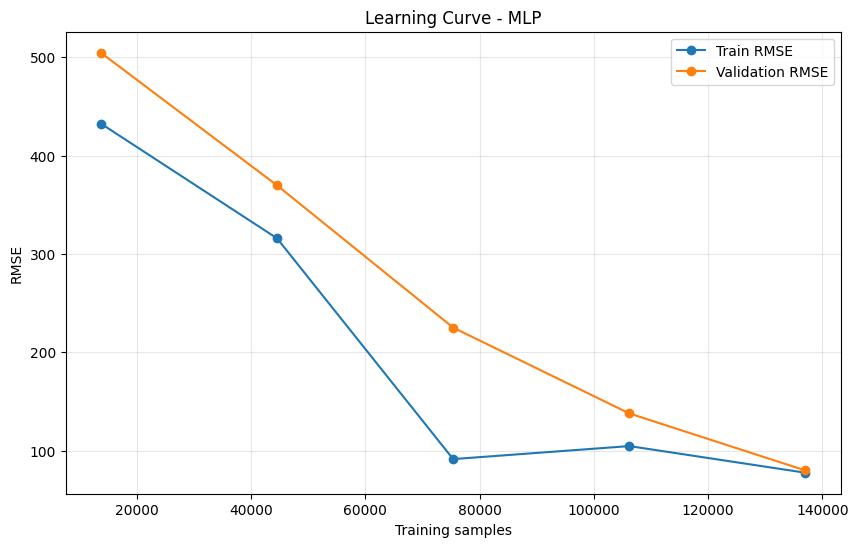

In [15]:
pred_train_mlp = model_mlp.predict(X_train_scaled).flatten()
pred_val_mlp = model_mlp.predict(X_val_scaled).flatten()
gap_mlp = evaluate_gap(y_train, pred_train_mlp, y_val, pred_val_mlp, "MLP")
addmet_mlp = evaluate_additional_metrics(y_val, pred_val_mlp, "MLP")
cv_mlp = cross_val_mlp(params={"learning_rate": 0.0005, "batch_size": 256, "epochs": 100 },X=X_train_scaled, y=y_train, tscv=tscv)
plot_learning_curve(model_mlp, X_train_scaled, y_train, "MLP")

In [16]:
id_test = test_df['id'].values

pred_test_mlp = model_mlp.predict(X_test_scaled).flatten()
joblib.dump(pred_val_mlp, '/kaggle/working/pred_val_mlp.pkl')

submission_mlp = pd.DataFrame({'id': id_test, 'num_sold': pred_test_mlp})
submission_mlp.to_csv('/kaggle/working/submission_mlp.csv', index=False)

3080/3080 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
